In [35]:
import pandas as pd
import numpy as np
import os

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [36]:
DATA_DIR = r"F:\EDAIC-WOZ\data"
LABEL_DIR = r"F:\EDAIC-WOZ\labels"

print("Data directory:", DATA_DIR)
print("Label directory:", LABEL_DIR)

print("Data folder exists:", os.path.exists(DATA_DIR))
print("Label folder exists:", os.path.exists(LABEL_DIR))

Data directory: F:\EDAIC-WOZ\data
Label directory: F:\EDAIC-WOZ\labels
Data folder exists: True
Label folder exists: True


In [37]:
train_labels = pd.read_csv(
    os.path.join(LABEL_DIR, "train_split.csv")
)

print("Train shape:", train_labels.shape)

print("\nColumns:")
print(train_labels.columns.tolist())

print("\nFirst 5 rows:")
display(train_labels.head())

Train shape: (163, 6)

Columns:
['Participant_ID', 'Gender', 'PHQ_Binary', 'PHQ_Score', 'PCL-C (PTSD)', 'PTSD Severity']

First 5 rows:


,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity
0,302,male,0,4,0,28
1,303,female,0,0,0,17
2,304,female,0,6,0,20
3,305,male,0,7,0,28
4,307,female,0,4,0,23


In [38]:
print("PHQ_Binary class distribution:")

print(
    train_labels["PHQ_Binary"]
    .value_counts()
    .sort_index()
)

print("\nClass percentages:")

print(
    train_labels["PHQ_Binary"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

PHQ_Binary class distribution:
PHQ_Binary
0    126
1     37
Name: count, dtype: int64

Class percentages:
PHQ_Binary
0    77.3
1    22.7
Name: proportion, dtype: float64


In [39]:
def extract_mfcc(pid):

    pid = int(pid)

    feature_path = os.path.join(
        DATA_DIR,
        f"{pid:03d}_P",
        "features",
        f"{pid:03d}_BoAW_openSMILE_2.3.0_MFCC.csv"
    )

    df = pd.read_csv(
        feature_path,
        header=None
    )

    # Remove first 2 metadata columns
    features = df.iloc[:, 2:]

    # Mean of each MFCC feature across all frames
    participant_features = features.mean(axis=0)

    return participant_features.values

In [40]:
X_list = []
y_list = []
participant_ids = []

for _, row in train_labels.iterrows():

    pid = row["Participant_ID"]

    try:
        features = extract_mfcc(pid)

        X_list.append(features)
        y_list.append(row["PHQ_Binary"])
        participant_ids.append(pid)

    except Exception as e:
        print(f"Error for participant {pid}: {e}")

X = np.array(X_list)
y = np.array(y_list)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (163, 100)
y shape: (163,)


In [41]:
print("Missing values in X:", np.isnan(X).sum())
print("Infinite values in X:", np.isinf(X).sum())

print("\nX dtype:", X.dtype)
print("y dtype:", y.dtype)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Missing values in X: 0
Infinite values in X: 0

X dtype: float64
y dtype: int32

X shape: (163, 100)
y shape: (163,)


In [42]:
model = Pipeline([
    ("selector", SelectKBest(
        score_func=f_classif,
        k=10
    )),

    ("scaler", StandardScaler()),

    ("svm", LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

print(model)

Pipeline(steps=[('selector', SelectKBest()), ('scaler', StandardScaler()),
                ('svm',
                 LinearSVC(class_weight='balanced', max_iter=5000,
                           random_state=42))])


In [43]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [44]:
scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print("5-Fold F1 Scores:")

for i, score in enumerate(scores, 1):
    print(f"Fold {i}: {score:.4f}")

5-Fold F1 Scores:
Fold 1: 0.3000
Fold 2: 0.3077
Fold 3: 0.4615
Fold 4: 0.4000
Fold 5: 0.4800


In [45]:
mean_f1 = scores.mean()
std_f1 = scores.std()

print("=" * 45)
print(f"Mean F1: {mean_f1:.4f}")
print(f"Std F1:  {std_f1:.4f}")
print(f"F1 Score: {mean_f1:.4f} ± {std_f1:.4f}")
print("=" * 45)

Mean F1: 0.3898
Std F1:  0.0751
F1 Score: 0.3898 ± 0.0751


In [46]:
oof_predictions = cross_val_predict(
    model,
    X,
    y,
    cv=cv
)

print(
    "Out-of-fold predictions shape:",
    oof_predictions.shape
)

Out-of-fold predictions shape: (163,)


In [47]:
print("Classification Report:")

print(
    classification_report(
        y,
        oof_predictions,
        target_names=[
            "Non-Depressed",
            "Depressed"
        ]
    )
)

Classification Report:
               precision    recall  f1-score   support

Non-Depressed       0.83      0.63      0.72       126
    Depressed       0.31      0.57      0.40        37

     accuracy                           0.62       163
    macro avg       0.57      0.60      0.56       163
 weighted avg       0.72      0.62      0.65       163



Confusion Matrix:
[[80 46]
 [16 21]]


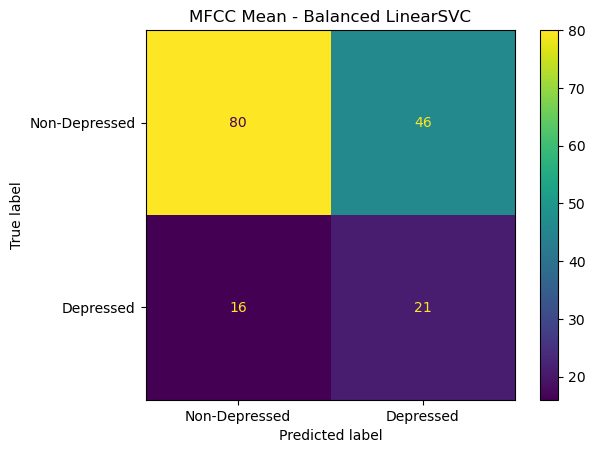

In [48]:
cm = confusion_matrix(
    y,
    oof_predictions
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Non-Depressed",
        "Depressed"
    ]
)

disp.plot()

plt.title("MFCC Mean - Balanced LinearSVC")
plt.show()

In [54]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# OOF predictions
y_pred = cross_val_predict(
    model,
    X,
    y,
    cv=cv,
    method="predict"
)

# Metrics
mean_f1 = scores.mean()
std_f1 = scores.std()

accuracy = accuracy_score(y, y_pred)
dep_precision = precision_score(y, y_pred, pos_label=1)
dep_recall = recall_score(y, y_pred, pos_label=1)
dep_f1 = f1_score(y, y_pred, pos_label=1)

# Number of input features
input_features = X.shape[1]

print("=" * 120)
print("MFCC MEAN — FINAL RESULTS")
print("=" * 120)

print(f"Model:              LinearSVC + Balanced Class Weight")
print(f"Features:           Mean")
print(f"Input Features:     {input_features}")
print(f"Selected Features:  10")
print(f"CV Folds:            5")
print(f"Mean F1:             {mean_f1:.6f}")
print(f"Std F1:              {std_f1:.6f}")
print(f"Accuracy:            {accuracy:.6f}")
print(f"Depressed Precision: {dep_precision:.6f}")
print(f"Depressed Recall:    {dep_recall:.6f}")
print(f"Depressed F1:        {dep_f1:.6f}")
print("=" * 120)

MFCC MEAN — FINAL RESULTS
Model:              LinearSVC + Balanced Class Weight
Features:           Mean
Input Features:     100
Selected Features:  10
CV Folds:            5
Mean F1:             0.389846
Std F1:              0.075090
Accuracy:            0.619632
Depressed Precision: 0.313433
Depressed Recall:    0.567568
Depressed F1:        0.403846
